# 07 — Macroscopic interface operators against exact Maxwell fields

**Question.** Are our operators $Q$, $T$ and $Q^{-1}$ correct and fast enough for macroscopic interfaces, where the lattice pipeline $R\,Q^{-1}TQ\,R$ cannot run?

Everything here is compared with exact Maxwell solutions, never with another approximation:

* **Single spherical interface** (stable first Debye term of the sphere, exact to $10^{-10}$ up to $ka=10^5$): checks $Q$, $T$ and $Q^{-1}$ separately.
* **Glass ball lens** (Lorenz–Mie for an axial beam): its Debye term $p=1$ — the wave that crosses both faces once — is exactly the physics of our one-way pipeline; the full Mie field adds every internal return.

Two implementations of the same operators are tested:

* **Lattice**: $Q$ on the tangent-plane FFT lattice and the **explicit** $Q^{-1}$ (Love equivalence with the Weyl expansion from both tangential traces; no iterative fit).
* **Phase space**: fields as local plane-wave atoms whose carriers are removed; $R$, $Q$, $T$ and the explicit $Q^{-1}$ act atom by atom (docs/phase_space_operators).

Ray transport appears only as an alternative $Q^{-1}$ between $\Sigma$ and its tangent plane; propagation beyond a plane is always exact ASM. Full-wave solvers (PMCHWT and Müller BEM, FEM, Mie) on wavelength-scale bodies are in notebook 06.

Heavy results are cached in the repository's `.cache/`; the data live in `interface_operators.py`.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import vecdiff_general as optics
from matplotlib.colors import LogNorm, Normalize
from vecdiff_general.visualization import plot_polarization
from IPython.display import Markdown, display

import interface_operators as io

warnings.simplefilter("ignore")
%matplotlib inline
plt.rcParams.update({"figure.dpi": 150, "font.size": 11})


def table(header, rows):
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(str(v) for v in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))

## 1. The exact references

A plane wave meets one spherical interface (entry face: air → glass, $n=1.5$; exit face: glass → air). The reference is the first Debye term of the sphere, evaluated with ratio recurrences so that it stays finite for macroscopic spheres. Each stored case is checked against the interface conditions themselves: tangential $\mathbf E$ and $\mathbf H$ must be continuous across the sphere.

In [2]:
rows = []
for face in ("entry", "exit"):
    for ka in io.GROUND_SIZES:
        d = io.ground_truth(ka, face)
        rows.append((face, f"{ka:.0e}", f"{float(d['radius']):.0f}", f"{float(d['radius']) * 0.532e-3:.2f}",
                     f"{float(d['tangential_E_jump']):.1e}", f"{float(d['tangential_H_jump']):.1e}", f"{float(d['seconds']):.0f}"))
table(("Face", "Size parameter ka", "Radius (λ)", "Radius at 532 nm (mm)", "Tangential E jump", "Tangential H jump", "Reference time (s)"), rows)

| Face | Size parameter ka | Radius (λ) | Radius at 532 nm (mm) | Tangential E jump | Tangential H jump | Reference time (s) |
|---|---|---|---|---|---|---|
| entry | 1e+03 | 159 | 0.08 | 3.1e-13 | 2.5e-13 | 1 |
| entry | 3e+03 | 477 | 0.25 | 6.9e-13 | 4.8e-13 | 3 |
| entry | 1e+04 | 1592 | 0.85 | 3.5e-12 | 3.1e-12 | 9 |
| entry | 3e+04 | 4775 | 2.54 | 2.5e-11 | 2.8e-11 | 35 |
| entry | 1e+05 | 15915 | 8.47 | 9.2e-11 | 8.1e-11 | 242 |
| exit | 1e+03 | 106 | 0.06 | 1.2e-13 | 1.8e-13 | 1 |
| exit | 3e+03 | 318 | 0.17 | 5.2e-13 | 6.9e-13 | 2 |
| exit | 1e+04 | 1061 | 0.56 | 1.8e-12 | 3.2e-12 | 5 |
| exit | 3e+04 | 3183 | 1.69 | 5.7e-12 | 6.9e-12 | 28 |
| exit | 1e+05 | 10610 | 5.64 | 4.3e-11 | 6.4e-11 | 217 |

## 2. Phase-space pipeline on a macroscopic interface

The incident plane wave (apodized by a smooth edge at $0.36R$) is represented by plane atoms, taken onto the sphere by $Q$, transmitted by $T$, returned to plane atoms by the explicit $Q^{-1}$ and propagated by exact $R$ to a window just past the cap. $Q$ and $T$ are checked on the surface, the whole pipeline on the window. At these sizes the lattice pipeline exceeds five minutes.

| Size parameter ka | Radius (λ) | Atoms | Envelope grid per atom: plane / surface / output | Q error on Σ | T error on Σ | Pipeline error past the cap | Wall time (s) |
|---|---|---|---|---|---|---|---|
| 1e+04 | 1592 | 292 | 52 / 52 / 80 | 1.0e-08 | 2.8e-05 | 2.2e-06 | 8.1 |
| 3e+04 | 4775 | 637 | 52 / 52 / 88 | 8.0e-09 | 1.1e-05 | 7.5e-07 | 18.6 |

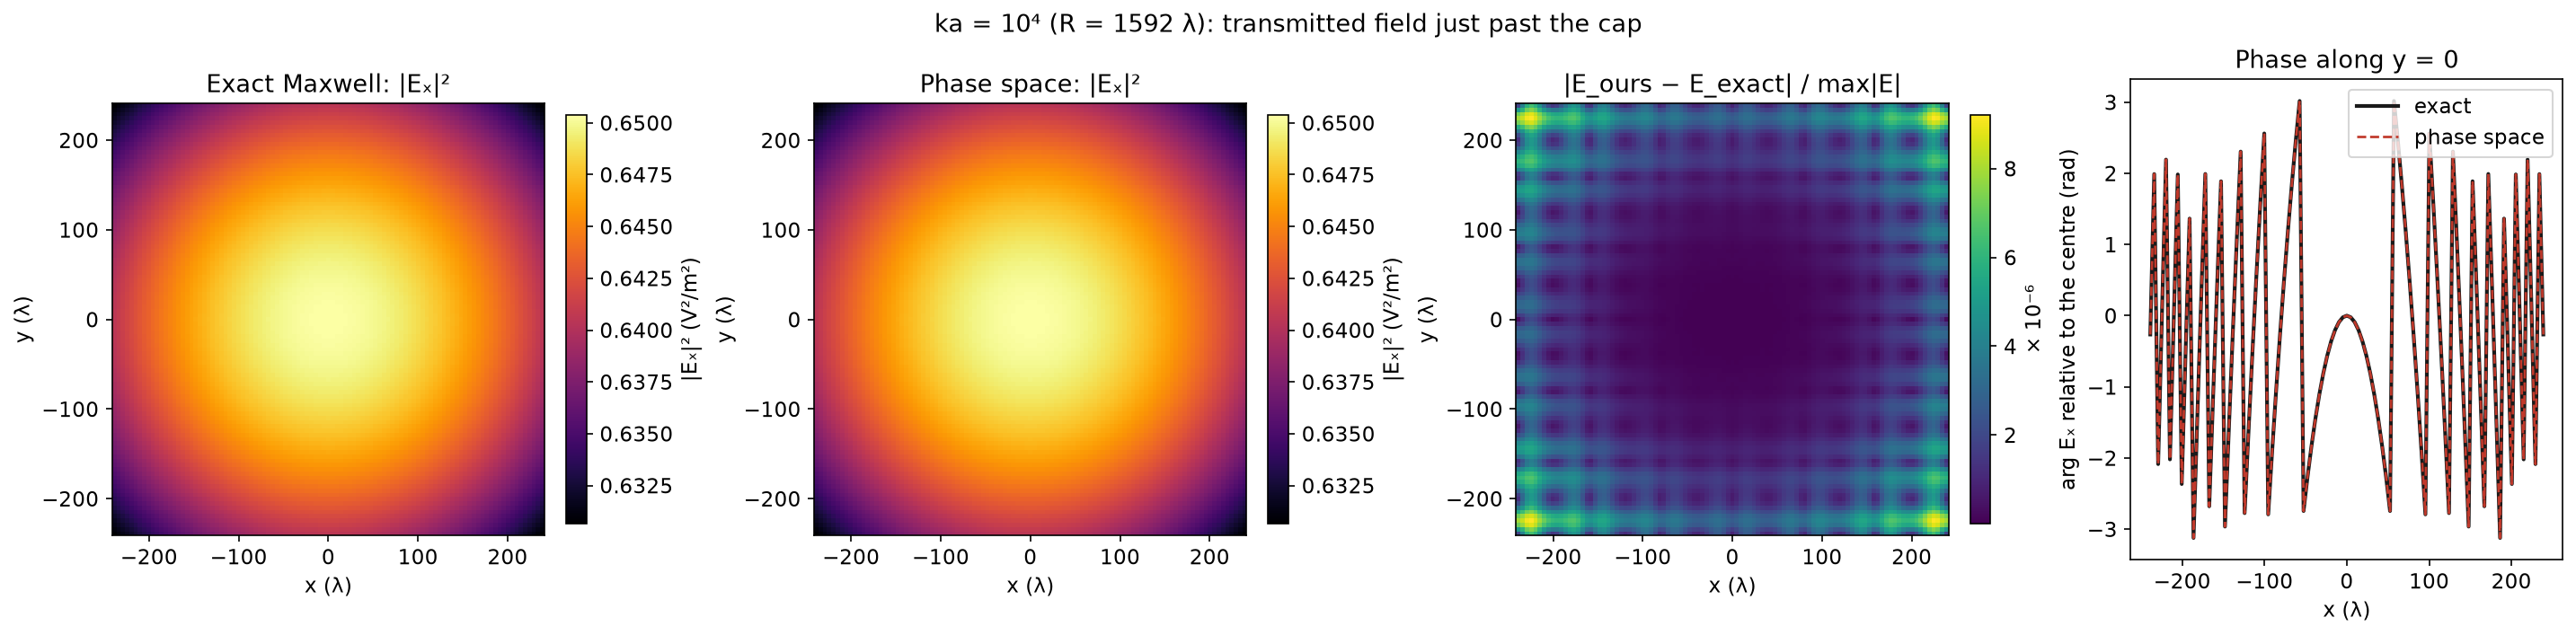

In [3]:
cases = {ka: io.phase_space_sphere(ka, tile=tile) for ka, tile in ((1e4, 80.0), (3e4, 160.0))}
rows = []
for ka, d in cases.items():
    total = sum(float(v) for k, v in d.items() if k.startswith("seconds"))
    rows.append((f"{ka:.0e}", f"{float(d['radius']):.0f}", int(d["atoms"]), " / ".join(str(int(g)) for g in d["grids"]),
                 f"{float(d['error_Q']):.1e}", f"{float(d['error_T']):.1e}", f"{float(d['error_window']):.1e}", f"{total:.1f}"))
table(("Size parameter ka", "Radius (λ)", "Atoms", "Envelope grid per atom: plane / surface / output", "Q error on Σ", "T error on Σ",
       "Pipeline error past the cap", "Wall time (s)"), rows)

d = cases[1e4]
X, Y = d["dense_x"], d["dense_y"]
exact, ours = d["dense_exact"], d["dense_ours"]
fig, axes = plt.subplots(1, 4, figsize=(19, 4.6), layout="constrained")
top = np.abs(exact[..., 0]).max() ** 2
for ax, values, title in ((axes[0], abs(exact[..., 0]) ** 2, "Exact Maxwell: |Eₓ|²"), (axes[1], abs(ours[..., 0]) ** 2, "Phase space: |Eₓ|²")):
    im = ax.pcolormesh(X, Y, values, cmap="inferno", shading="nearest", norm=Normalize(values.min(), top))
    ax.set(aspect="equal", title=title, xlabel="x (λ)", ylabel="y (λ)")
    fig.colorbar(im, ax=ax, label="|Eₓ|² (V²/m²)", shrink=0.85)
difference = np.linalg.norm(ours - exact, axis=-1) / np.abs(exact[..., 0]).max()
im = axes[2].pcolormesh(X, Y, difference * 1e6, cmap="viridis", shading="nearest")
axes[2].set(aspect="equal", title="|E_ours − E_exact| / max|E|", xlabel="x (λ)", ylabel="y (λ)")
fig.colorbar(im, ax=axes[2], label="× 10⁻⁶", shrink=0.85)
row = X.shape[0] // 2
reference_phase = np.conj(exact[row, row, 0])
axes[3].plot(X[row], np.angle(exact[row, :, 0] * reference_phase), "-", color="0.1", lw=2, label="exact")
axes[3].plot(X[row], np.angle(ours[row, :, 0] * reference_phase), "--", color="#c0392b", lw=1.3, label="phase space")
axes[3].set(xlabel="x (λ)", ylabel="arg Eₓ relative to the centre (rad)", title="Phase along y = 0")
axes[3].legend()
fig.suptitle(f"ka = 10⁴ (R = {float(d['radius']):.0f} λ): transmitted field just past the cap")
plt.show()

The difference map shows the tile pattern of the atoms: the residual is the truncation of their windows and bands, bounded by the requested tolerance, not a model error.

## 3. A glass ball lens: two interfaces and a focus

A flat-top beam (radius $35\lambda$, $1.5\lambda$ erf edge) crosses a glass sphere of radius $R=100\lambda$. Our lattice pipeline: exact incident beam on the entry cap → $T$ → explicit $Q^{-1}$ → ASM to the exit tangent plane → $Q$ onto the exit cap → $T$ → explicit $Q^{-1}$. The exact Debye term $p=1$ carries the same physics; the full Mie field adds the internal reflections our one-way model omits by design.

Maps follow the reference style: transverse intensity divided by the exact on-axis value, logarithmic from $10^{-5}$ to 1, so side lobes and minima stay distinct; black segments give the transverse polarization direction. The focal window holds three side lobes on each side.

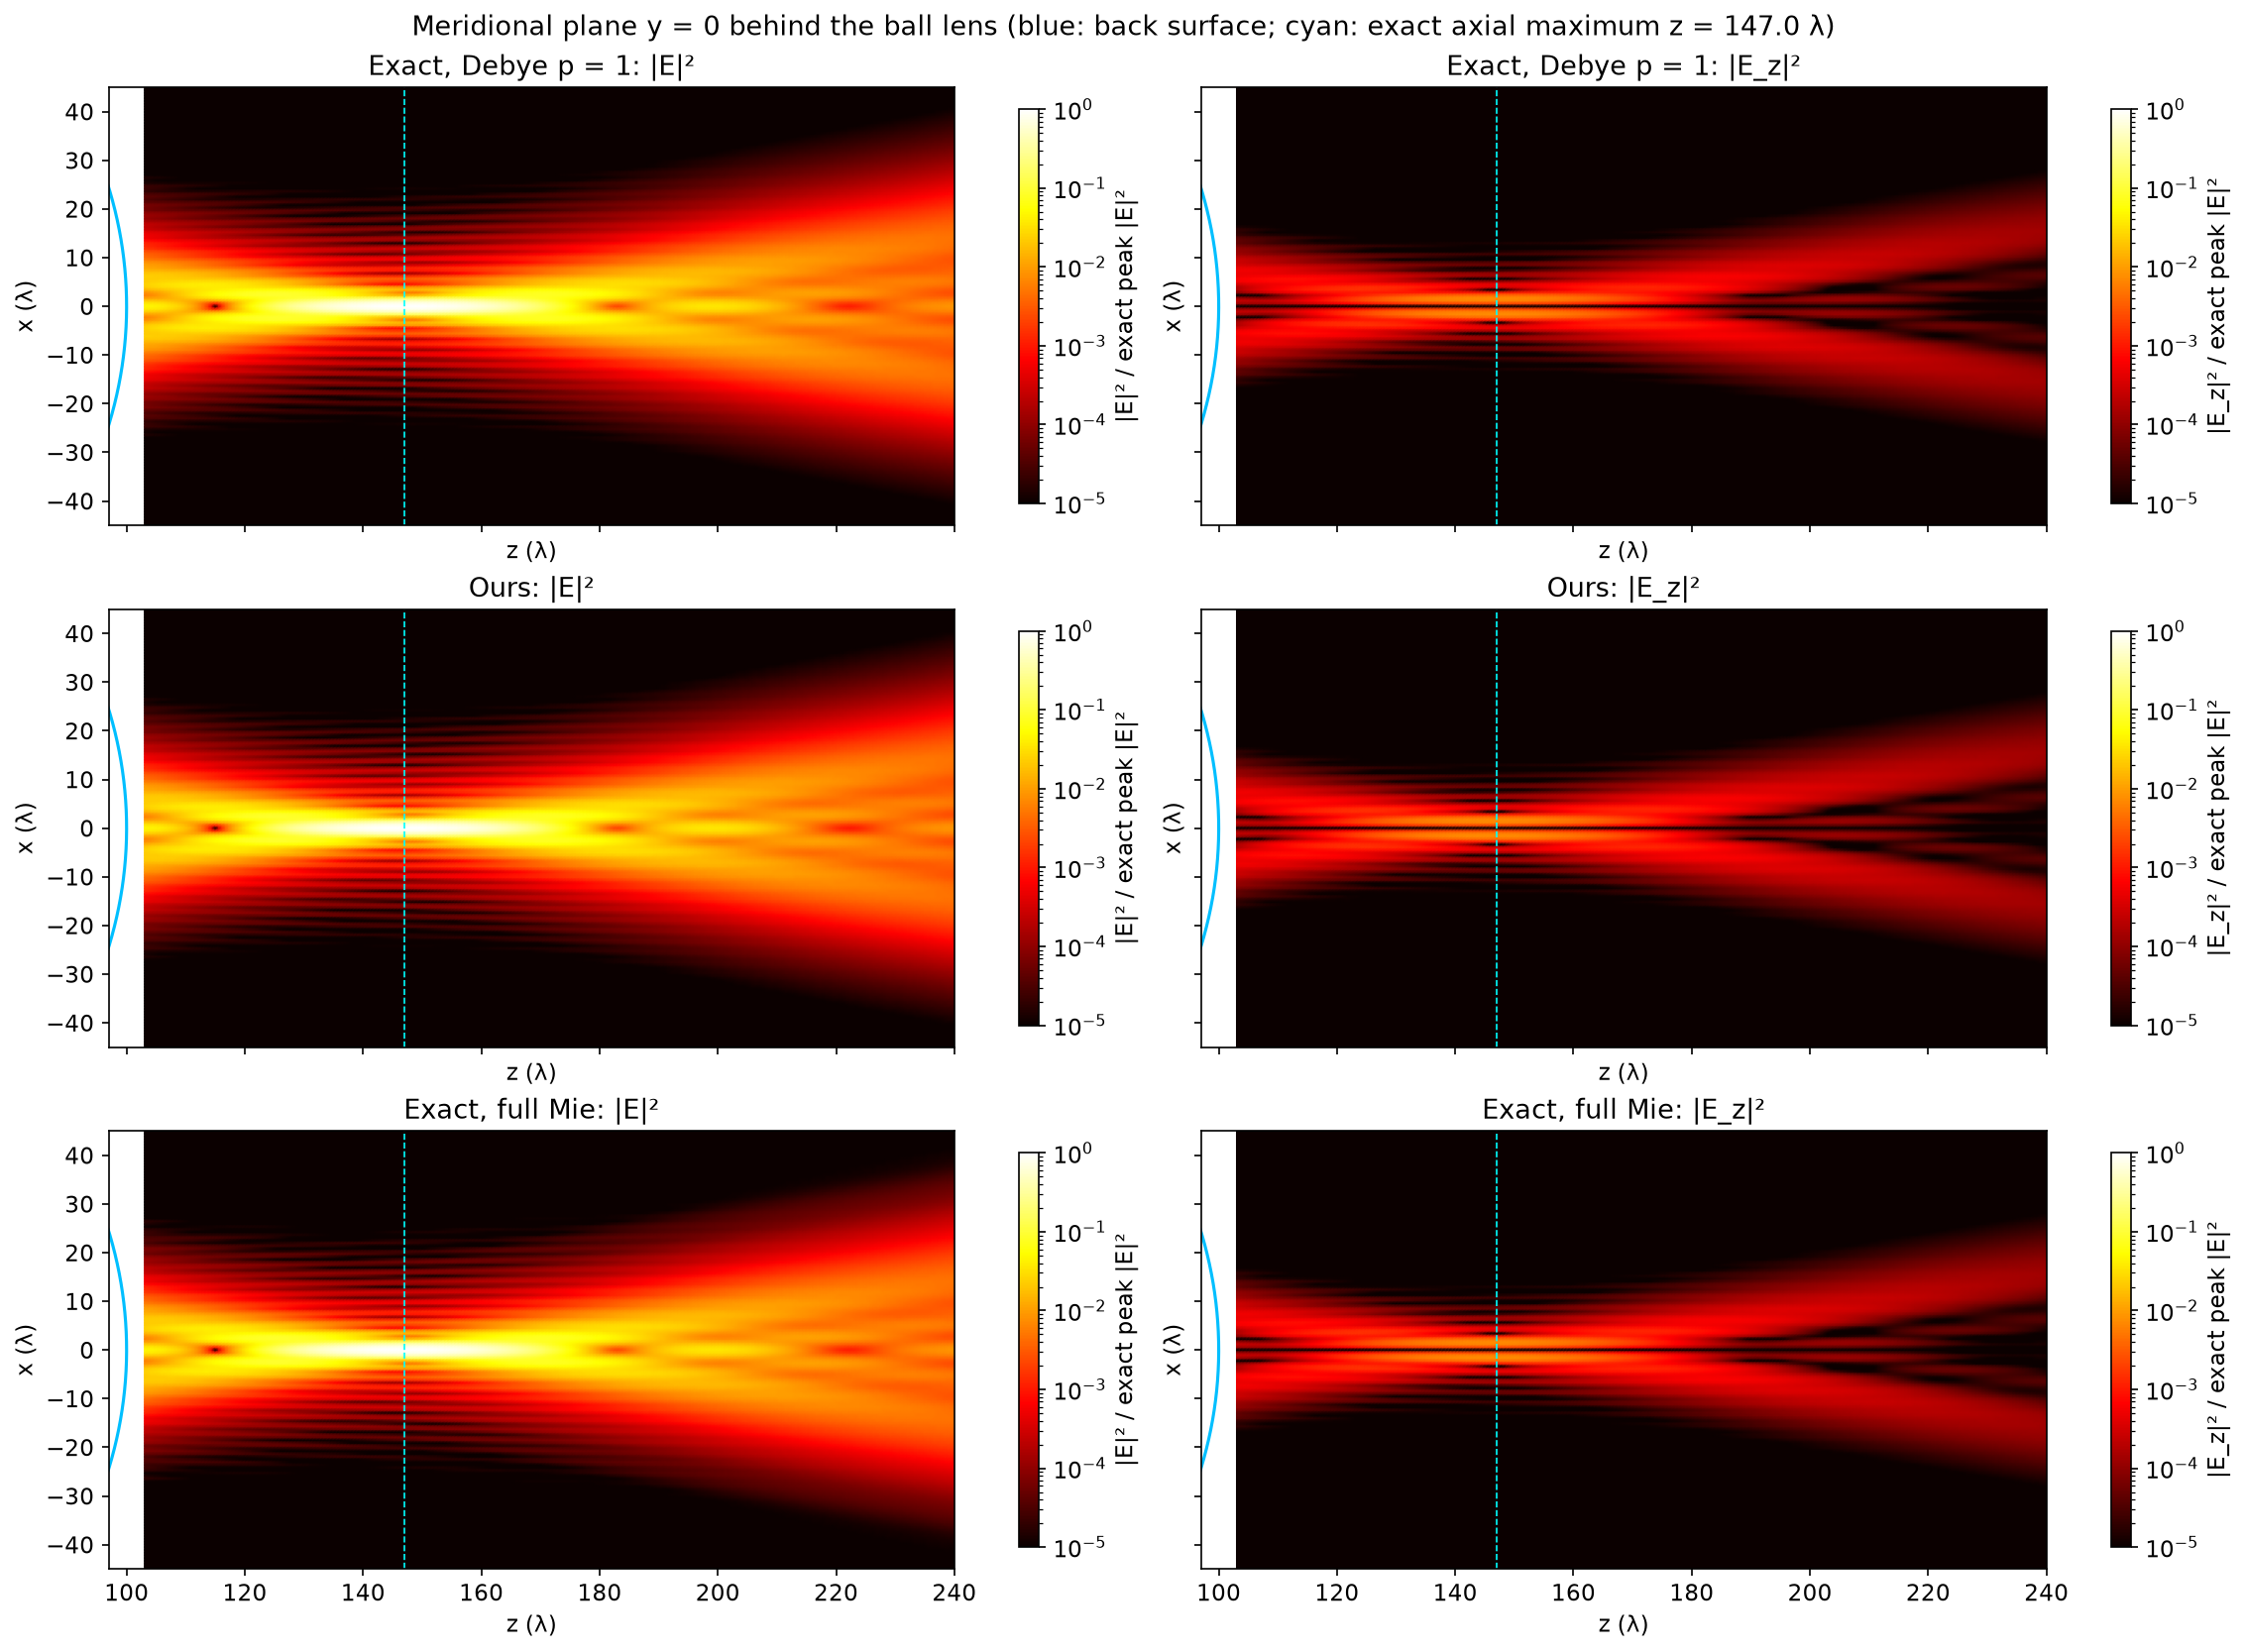

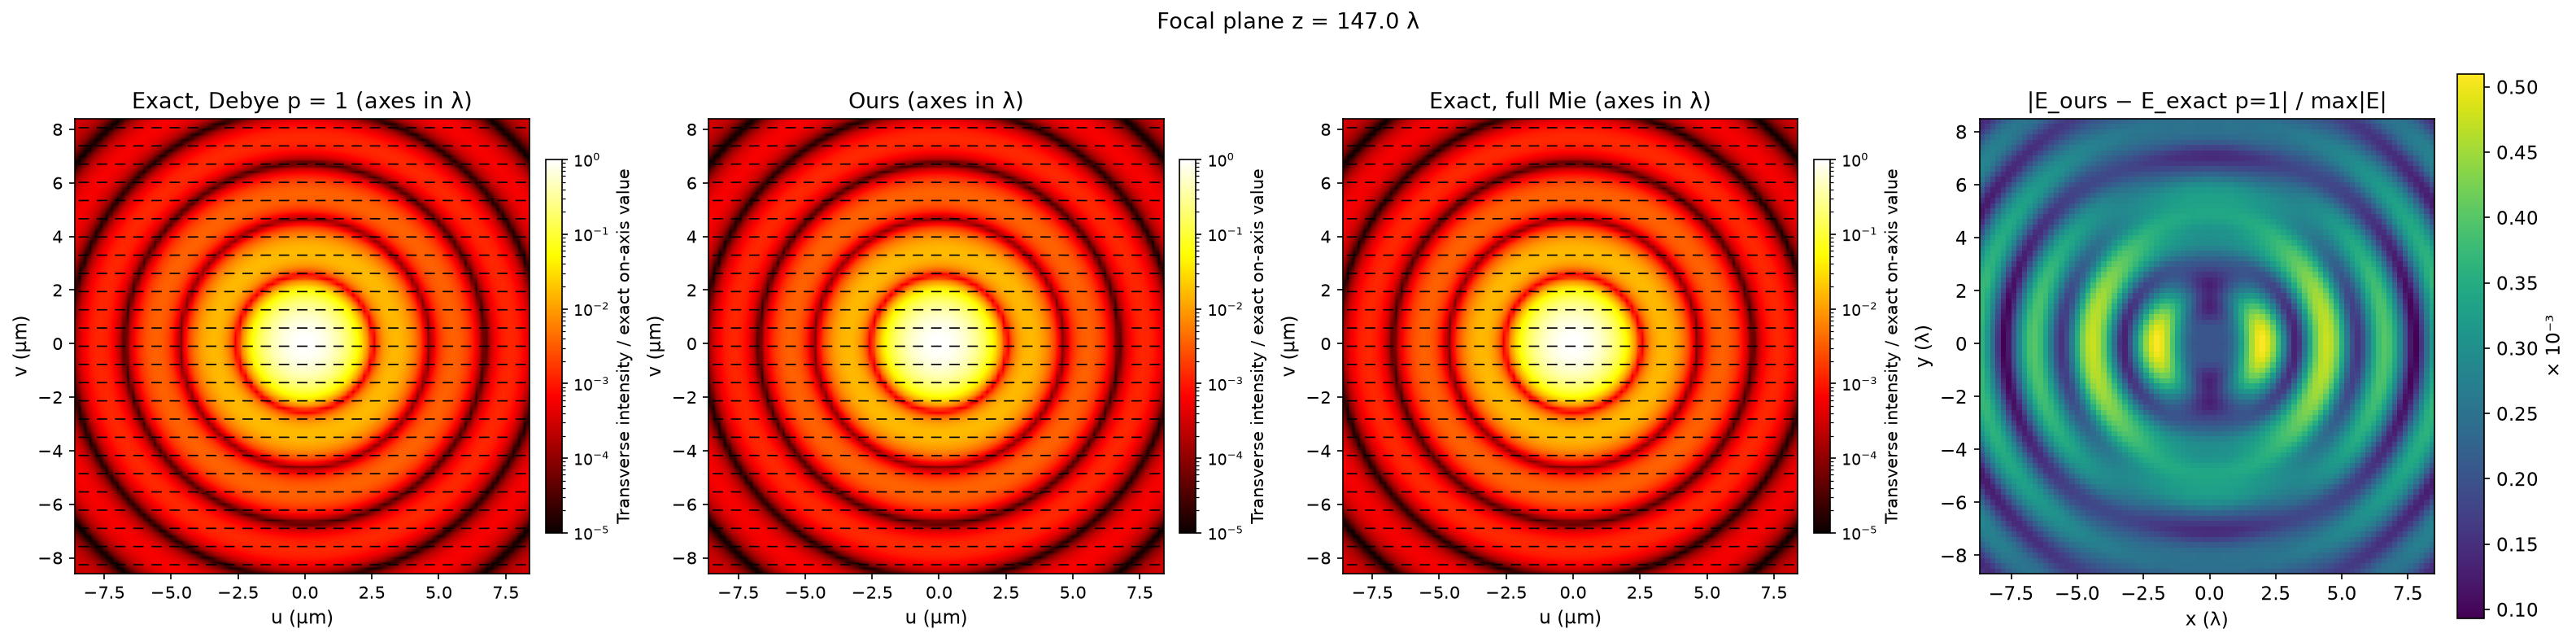

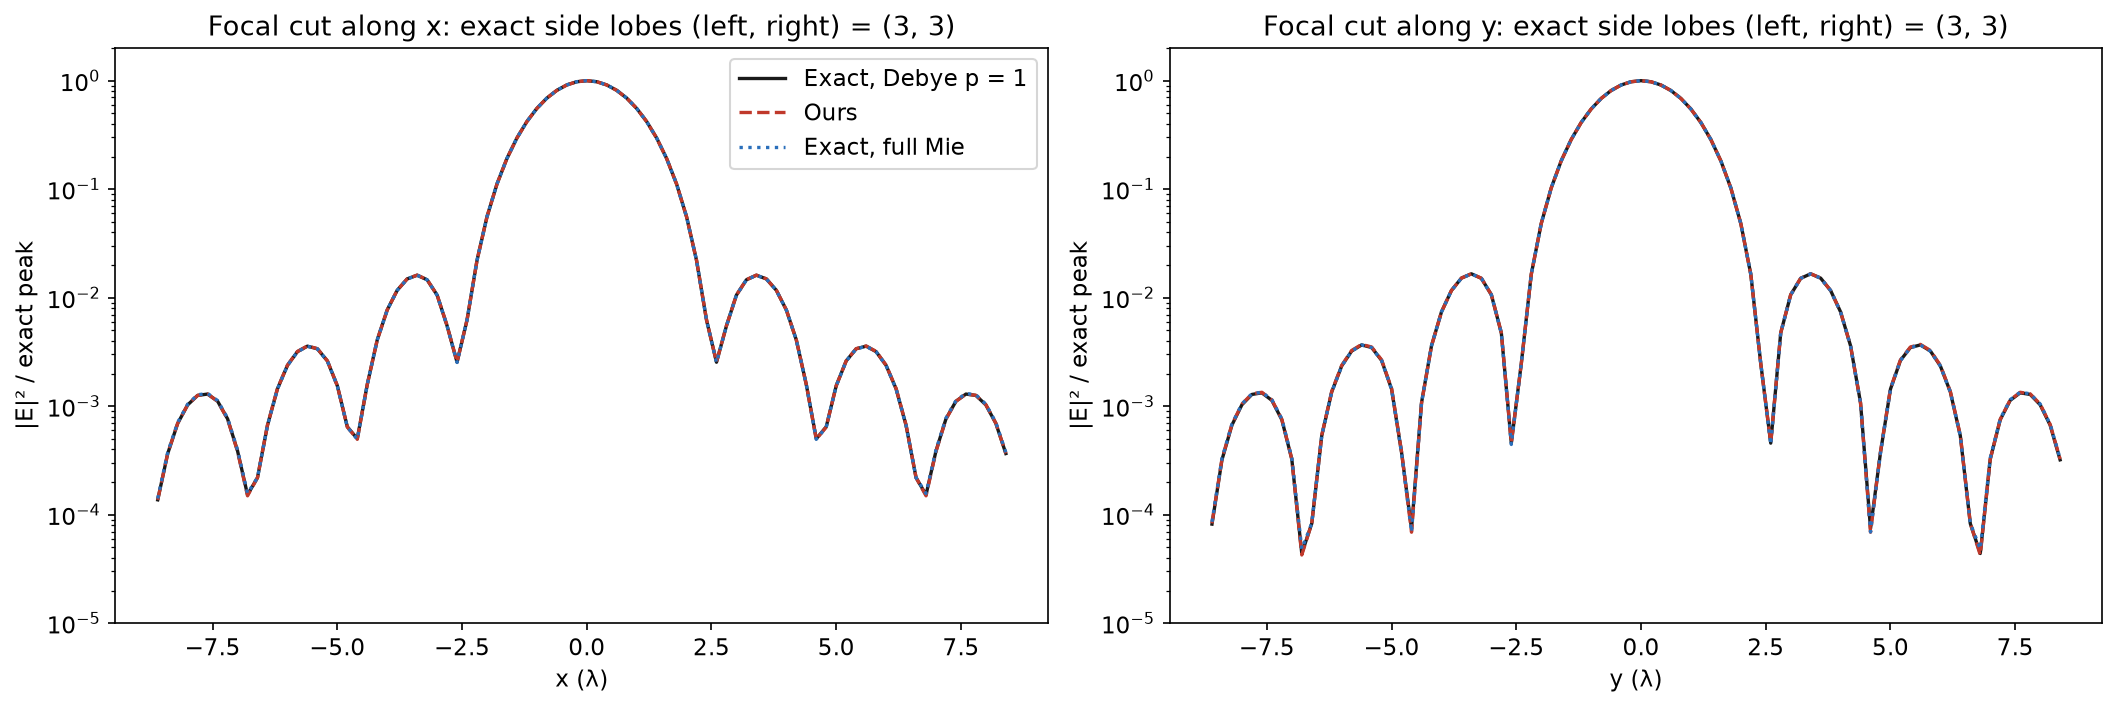

| Compared with | Meridional section: relative error | Focal plane: relative error |
|---|---|---|
| Exact Debye p = 1 (same physics) | 2.9e-03 | 2.1e-03 |
| Exact full Mie (with internal returns) | 4.7e-03 | 3.4e-03 |

In [4]:
ball = io.ball_comparison()
R, focus = io.BALL["radius"], float(ball["focus"])
section = ball["section"]
X, Z = section[..., 0], section[..., 2]


def norm2(E):
    return np.sum(abs(E) ** 2, -1)


rows = [("Exact, Debye p = 1", ball["exact_section_p1"]), ("Ours", ball["ours_section_E"]), ("Exact, full Mie", ball["exact_section_total"])]
peak = norm2(ball["exact_section_p1"]).max()
fig, axes = plt.subplots(3, 2, figsize=(15, 11), layout="constrained", sharex=True, sharey=True)
arc = np.linspace(np.pi / 2 - 0.5, np.pi / 2 + 0.5, 200)
for r, (title, E) in enumerate(rows):
    for c, (values, label) in enumerate(((norm2(E), "|E|²"), (abs(E[..., 2]) ** 2, "|E_z|²"))):
        ax = axes[r, c]
        im = ax.pcolormesh(Z, X, np.maximum(values / peak, 1e-5), cmap="hot", shading="gouraud", norm=LogNorm(1e-5, 1))
        ax.plot(R * np.sin(arc), R * np.cos(arc), color="deepskyblue", lw=1.5)
        ax.axvline(focus, color="cyan", ls="--", lw=0.8)
        ax.set(title=f"{title}: {label}", xlabel="z (λ)", ylabel="x (λ)", xlim=(R - 3, 240), ylim=(-45, 45))
        fig.colorbar(im, ax=ax, label=f"{label} / exact peak |E|²", shrink=0.9)
fig.suptitle(f"Meridional plane y = 0 behind the ball lens (blue: back surface; cyan: exact axial maximum z = {focus:.1f} λ)")
plt.show()

plane = ball["plane"]
keep = np.flatnonzero(np.abs(plane[0, :, 0]) <= 8.6)  # between the third and fourth side lobes
plane = plane[np.ix_(keep, keep)]
fields = [
    ("Exact, Debye p = 1", ball["exact_plane_p1"], ball["exact_plane_p1_H"]),
    ("Ours", ball["ours_plane_E"], ball["ours_plane_H"]),
    ("Exact, full Mie", ball["exact_plane_total"], ball["exact_plane_total_H"]),
]
fields = [(t, E[np.ix_(keep, keep)], H[np.ix_(keep, keep)]) for t, E, H in fields]
centre = plane.shape[0] // 2
on_axis = float(np.sum(abs(fields[0][1][centre, centre, :2]) ** 2))
grid = optics.CartesianGrid(plane[0, :, 0] * 1e-6, plane[:, 0, 1] * 1e-6, optics.Frame([0, 0, focus * 1e-6]))  # λ = 1 µm
fig, axes = plt.subplots(1, 4, figsize=(21, 5.3), layout="constrained")
for ax, (title, E, H) in zip(axes[:3], fields):
    plot_polarization(optics.ElectromagneticField(optics.ElectricField(grid, 1e-6, E), H), axis=ax, title=f"{title} (axes in λ)",
                      crop=False, glyph="line", glyph_color="black", size_scale=None, cmap="hot", norm=LogNorm(1e-5, 1),
                      reference_intensity=on_axis, density=3.0, colorbar_label="Transverse intensity / exact on-axis value",
                      min_intensity_fraction=1e-5)
difference = np.linalg.norm(fields[1][1] - fields[0][1], axis=-1) / np.sqrt(norm2(fields[0][1]).max())
im = axes[3].pcolormesh(plane[..., 0], plane[..., 1], difference * 1e3, cmap="viridis", shading="nearest")
axes[3].set(aspect="equal", title="|E_ours − E_exact p=1| / max|E|", xlabel="x (λ)", ylabel="y (λ)")
fig.colorbar(im, ax=axes[3], label="× 10⁻³", shrink=0.9)
fig.suptitle(f"Focal plane z = {focus:.1f} λ")
plt.show()


def side_lobes(cut):
    middle = len(cut) // 2
    inner = cut[1:-1]
    peaks = np.flatnonzero((inner > cut[:-2]) & (inner >= cut[2:])) + 1
    return int(np.sum(peaks < middle)), int(np.sum(peaks > middle))


fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), layout="constrained")
for ax, (cut, label) in zip(axes, ((np.s_[centre, :], "x"), (np.s_[:, centre], "y"))):
    coordinate = plane[centre, :, 0] if label == "x" else plane[:, centre, 1]
    for (title, E, _), style, color in zip(fields, ("-", "--", ":"), ("0.1", "#c0392b", "#2a6fbb")):
        ax.semilogy(coordinate, norm2(E)[cut] / norm2(fields[0][1]).max(), style, color=color, lw=1.6, label=title)
    ax.set(xlabel=f"{label} (λ)", ylabel="|E|² / exact peak", ylim=(1e-5, 2),
           title=f"Focal cut along {label}: exact side lobes (left, right) = {side_lobes(norm2(fields[0][1])[cut])}")
axes[0].legend()
plt.show()

gap = lambda a, b: np.linalg.norm(a - b) / np.linalg.norm(b)  # noqa: E731
table(("Compared with", "Meridional section: relative error", "Focal plane: relative error"),
      [("Exact Debye p = 1 (same physics)", f"{gap(ball['ours_section_E'], ball['exact_section_p1']):.1e}", f"{gap(fields[1][1], fields[0][1]):.1e}"),
       ("Exact full Mie (with internal returns)", f"{gap(ball['ours_section_E'], ball['exact_section_total']):.1e}", f"{gap(fields[1][1], fields[2][1]):.1e}")])

Against the exact term with the same physics, the pipeline is accurate to a few $10^{-3}$ over the whole section and through every side lobe. The difference from full Mie is the internal reflection of the two faces (about 4 % in power per face), which a one-way model leaves out by construction.

## 4. Ray transport as $Q^{-1}$

Rays may replace $Q^{-1}$ only for the short hop from $\Sigma$ to its tangent plane; beyond it, ASM is exact in both paths. A converging glass → air sphere face ($ka=10^3$, focus at $2R$) is followed from the surface to the focus.

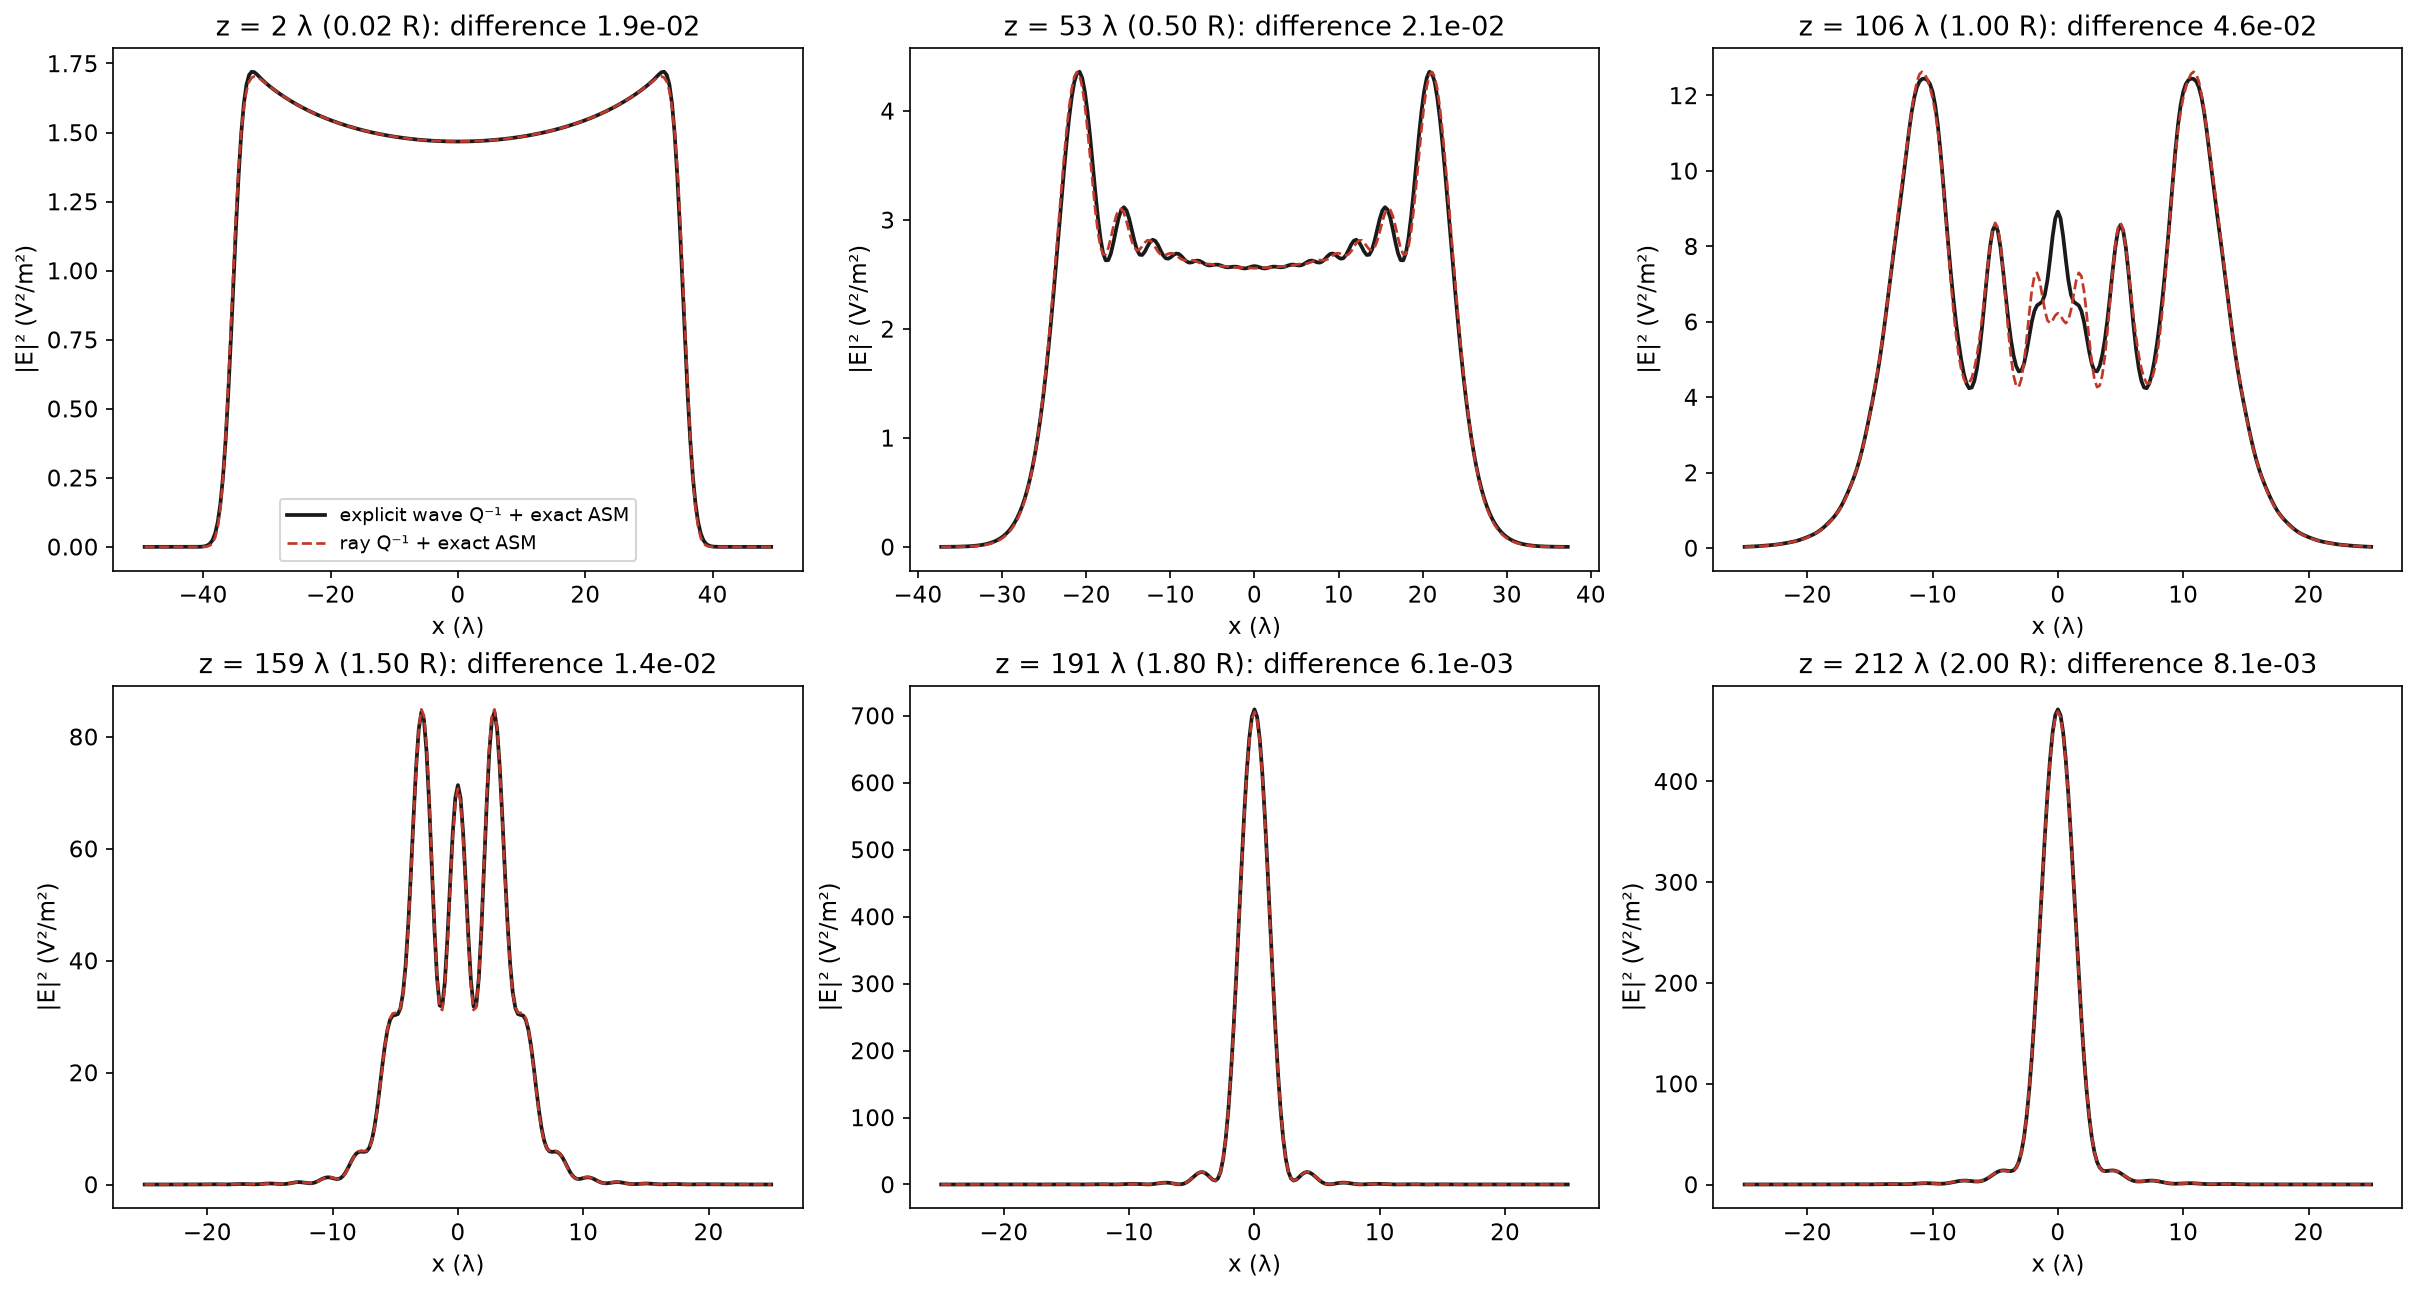

In [5]:
result = io.inverse_comparison(1000)
radius = result["radius"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5), layout="constrained")
for ax, plane in zip(axes.flat, result["planes_result"]):
    x = np.array(plane["x"])
    ax.plot(x, plane["wave_intensity"], "-", color="0.1", lw=1.8, label="explicit wave Q⁻¹ + exact ASM")
    ax.plot(x, plane["ray_intensity"], "--", color="#c0392b", lw=1.3, label="ray Q⁻¹ + exact ASM")
    ax.set(title=f"z = {plane['z']:.0f} λ ({plane['z'] / radius:.2f} R): difference {plane['relative_error']:.1e}", xlabel="x (λ)", ylabel="|E|² (V²/m²)")
axes.flat[0].legend(fontsize=9)
plt.show()

The two agree to within 1 % up to the focus except near $z=R$, where the edge wave of the aperture reaches the axis: the diffraction that happens over the sag is what rays leave out.

## 5. Accuracy and cost against size

Lattice pipeline with the explicit $Q^{-1}$ (measured here at $ka=10^3$) and the phase-space pipeline (section 2), both against the exact references.

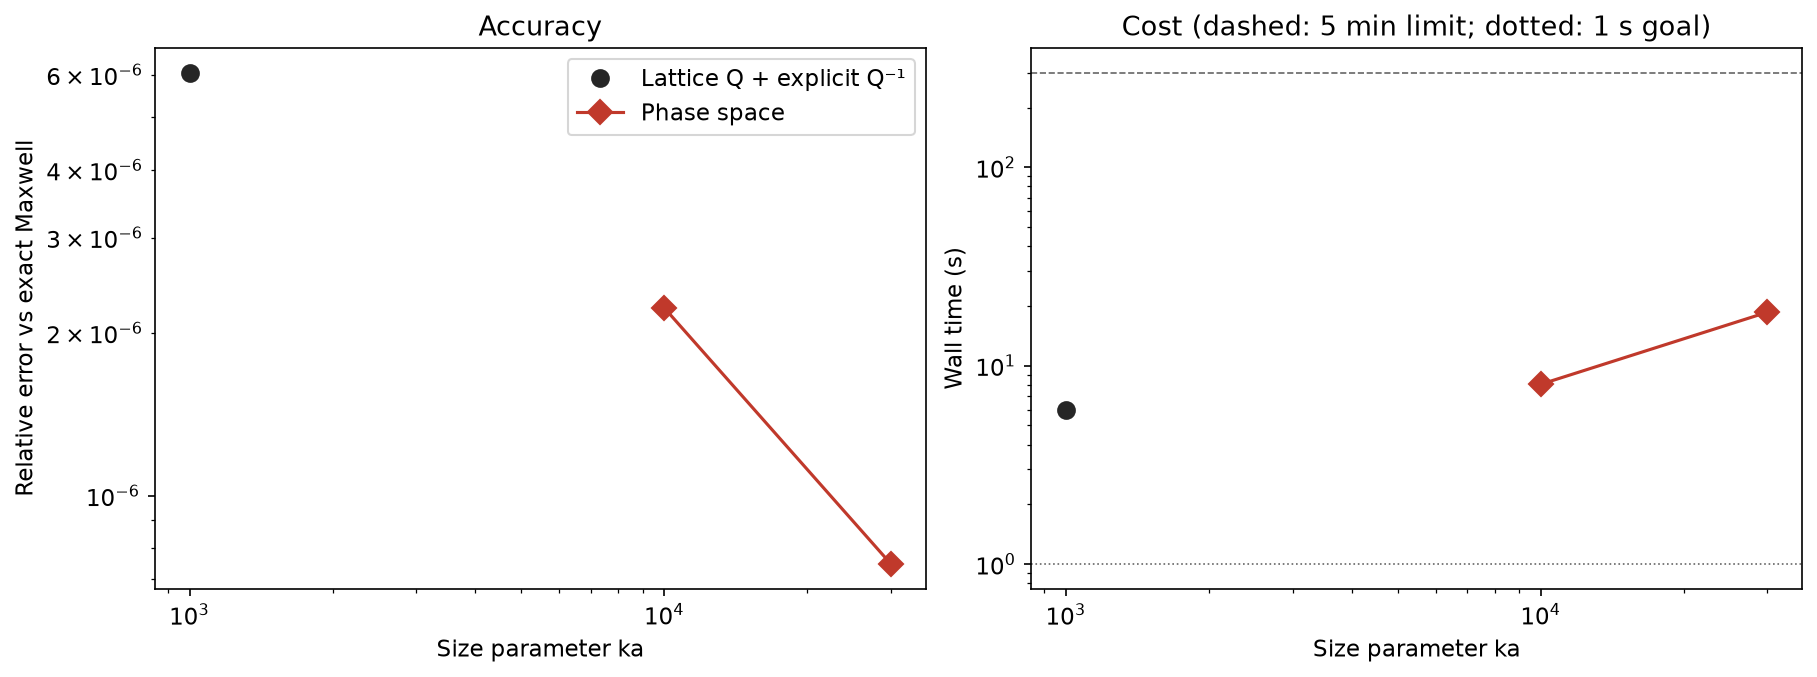

In [6]:
lattice = io.sphere_case(1000)
sizes = [1e3] + list(cases)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), layout="constrained")
axes[0].loglog([1e3], [lattice["relative_error"]], "o", color="0.15", ms=8, label="Lattice Q + explicit Q⁻¹")
axes[1].loglog([1e3], [sum(lattice["seconds"].values())], "o", color="0.15", ms=8, label="Lattice Q + explicit Q⁻¹")
axes[0].loglog(list(cases), [float(d["error_window"]) for d in cases.values()], "D-", color="#c0392b", ms=8, label="Phase space")
axes[1].loglog(list(cases), [sum(float(v) for k, v in d.items() if k.startswith("seconds")) for d in cases.values()],
               "D-", color="#c0392b", ms=8, label="Phase space")
axes[1].axhline(300, color="0.4", lw=0.8, ls="--")
axes[1].axhline(1, color="0.4", lw=0.8, ls=":")
axes[0].set(xlabel="Size parameter ka", ylabel="Relative error vs exact Maxwell", title="Accuracy")
axes[1].set(xlabel="Size parameter ka", ylabel="Wall time (s)", title="Cost (dashed: 5 min limit; dotted: 1 s goal)")
axes[0].legend()
plt.show()

## Conclusions

* $T$ is accurate at macroscopic scale; its error falls with size.
* The explicit $Q^{-1}$ reproduces exact fields without an iterative fit; on the ball lens the whole two-interface pipeline agrees with the exact $p=1$ field to a few $10^{-3}$ through the focus and all its side lobes.
* The phase-space operators keep this accuracy where lattices cannot run ($ka = 10^4$–$3\times10^4$), in seconds rather than hours; they do not yet meet the one-second target.
* Wavelength-scale bodies, where local Fresnel transmission is not valid, are compared with PMCHWT and Müller BEM, FEM and Mie in notebook 06.